# Lab Assignment: English-to-German Machine Translation with a Transformer

**Objective:**
The goal of this assignment is to fine-tune a pre-trained **Transformer** model for machine translation. You will load a dataset, fine-tune the model, and evaluate it using the BLEU score.

You will also compare your new model's performance and architecture against a previous **LSTM-based** model, and visualize the **self-attention** and **cross-attention** mechanisms that make the Transformer so powerful.


## Part 1: Setup and Environment

First, install all the necessary libraries.

In [1]:
!pip install -q transformers datasets evaluate sacrebleu sentencepiece sacremoses accelerate bertviz

import os
os.environ["USE_TF"] = "0"   # keep HF transformers on PyTorch (TensorFlow is only used for the LSTM in Part 5)

import torch, transformers
print("transformers", transformers.__version__, "| torch", torch.__version__)
print("GPU:", torch.cuda.is_available())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 91.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 8.3 MB/s eta 0:00:00
transformers 5.18.0 | torch 2.11.0+cu130
GPU: True


## Part 2: Data Loading and Pre-processing

### 1. Load the Dataset
We have to use previously provided dataset, which contains parallel sentences for English-to-German translation.

In [2]:
# Upload deu.txt (same file as Lab 8) AND s2s_eng_ger.h5 (LSTM saved in Lab 8).
from google.colab import files
from pathlib import Path
if not (Path("deu.txt").is_file() and Path("s2s_eng_ger.h5").is_file()):
    uploaded = files.upload()

import random
import pandas as pd
from datasets import Dataset, DatasetDict

DATA_PATH = "deu.txt"
SEED = 42
N_TRAIN, N_VAL, N_TEST = 20000, 1000, 1000   # subset keeps fine-tuning fast on a Colab T4

pairs = []
with open(DATA_PATH, encoding="utf-8") as f:
    for line in f.read().splitlines():
        parts = line.split("\t")
        if len(parts) >= 2 and parts[0].strip() and parts[1].strip():
            pairs.append({"en": parts[0].strip(), "de": parts[1].strip()})

print("Total sentence pairs in file:", len(pairs))
random.Random(SEED).shuffle(pairs)
pairs = pairs[: N_TRAIN + N_VAL + N_TEST]

raw_datasets = DatasetDict({
    "train":      Dataset.from_list(pairs[:N_TRAIN]),
    "validation": Dataset.from_list(pairs[N_TRAIN:N_TRAIN + N_VAL]),
    "test":       Dataset.from_list(pairs[N_TRAIN + N_VAL:]),
})
print(raw_datasets)
display(pd.DataFrame(raw_datasets["train"][:5]))

Saving deu.txt to deu.txt
Total sentence pairs in file: 331266
DatasetDict({
    train: Dataset({
        features: ['en', 'de'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['en', 'de'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['en', 'de'],
        num_rows: 1000
    })
})


,en,de
0,Tom never agrees with Mary.,Mit Mary ist Tom nie einer Meinung.
1,"Which goes faster, a ship or a train?","Was fährt schneller, ein Schiff oder ein Zug?"
2,I wish you didn't hang out with Tom. I don't l...,"Ich wollte, du gäbest dich nicht mit Tom ab. I..."
3,I feel unappreciated.,"Ich habe das Gefühl, nicht geschätzt zu werden."
4,I don't know who did it.,"Ich weiß nicht, wer es getan hat."


### 2. Load Tokenizer and Model
We will use a pre-trained model from the Helsinki-NLP group, `opus-mt-en-de`, which is a lightweight and efficient Transformer specifically designed for English-to-German translation.

In [3]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "Helsinki-NLP/opus-mt-en-de"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
print("Parameters: %.1fM" % (sum(p.numel() for p in model.parameters()) / 1e6))

config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/768k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/797k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  298MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Parameters: 74.4M


### 3. Pre-processing Function
We must tokenize both the English (input) and German (target) sentences. For seq2seq models, the tokenized target sentences are assigned to the `labels` key.

In [4]:
MAX_LEN = 128

def preprocess_function(examples):
    model_inputs = tokenizer(examples["en"], max_length=MAX_LEN, truncation=True)
    labels = tokenizer(text_target=examples["de"], max_length=MAX_LEN, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

### 4. Apply Pre-processing
Use the `.map()` function to apply this tokenization to the entire dataset.

In [5]:
tokenized_datasets = raw_datasets.map(
    preprocess_function, batched=True, remove_columns=["en", "de"]
)
print(tokenized_datasets)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1000
    })
})


## Part 3: Fine-Tuning the Model

### 1. Define Evaluation Metric (BLEU)
Machine translation is evaluated using the **BLEU score**. You can load the `sacrebleu` metric and create a `compute_metrics` function to use during training.

In [6]:
import numpy as np
import evaluate

metric = evaluate.load("sacrebleu")

def postprocess_text(preds, labels):
    return [p.strip() for p in preds], [[l.strip()] for l in labels]

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_preds, decoded_labels = postprocess_text(decoded_preds, decoded_labels)
    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    gen_len = np.mean([np.count_nonzero(p != tokenizer.pad_token_id) for p in preds])
    return {"bleu": result["score"], "gen_len": gen_len}

### 2. Configure Training
We will use the `Seq2SeqTrainer` and `Seq2SeqTrainingArguments` classes to manage the fine-tuning process.

In [10]:
from transformers import DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer

SAVE_PATH = "opus-mt-en-de-finetuned"

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

training_args = Seq2SeqTrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    num_train_epochs=3,
    warmup_steps=90,
    predict_with_generate=True,
    generation_max_length=MAX_LEN,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)


### 3. Start Training


In [11]:
# Baseline: pre-trained model BEFORE fine-tuning (validation BLEU) for reference
baseline = trainer.evaluate(tokenized_datasets["validation"], metric_key_prefix="baseline")
print("Baseline BLEU before fine-tuning:", round(baseline["baseline_bleu"], 2))

train_result = trainer.train()

trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)
print("Saved fine-tuned model to", SAVE_PATH)

Training Loss,Validation Loss,Epoch,Bleu,Gen Len
No log,0.775978,0,47.294577,9.263000


Baseline BLEU before fine-tuning: 47.29


Epoch,Training Loss,Validation Loss,Bleu,Gen Len
1,0.699379,0.607642,49.741360,9.372000
2,0.589049,0.599824,50.522269,9.357000
3,0.511043,0.599547,50.601742,9.369000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned model to opus-mt-en-de-finetuned


### 4. Evaluate the Model
After training, run the final evaluation on the test set.

In [12]:
test_results = trainer.evaluate(tokenized_datasets["test"], metric_key_prefix="test")
print("Test BLEU after fine-tuning: %.2f" % test_results["test_bleu"])
print("Test loss: %.4f" % test_results["test_loss"])

Training Loss,Validation Loss,Epoch,Bleu,Gen Len
0.511043,0.620416,3,49.843552,9.290000


Test BLEU after fine-tuning: 49.84
Test loss: 0.6204


## Part 4: Inference (Testing the Translator)

Now use your fine-tuned model to translate new sentences using the `pipeline` utility.

In [14]:
# Test with new sentences
text1 = "Hello, how are you doing today?"
text2 = "The transformer model is a powerful architecture for NLP."
text3 = "This assignment is for my machine learning lab."

# transformers v5 removed the "translation" pipeline, so we provide a drop-in
# replacement with the same call style/output format as pipeline(...).
device = 0 if torch.cuda.is_available() else -1
ft_tokenizer = AutoTokenizer.from_pretrained(SAVE_PATH)
ft_model = AutoModelForSeq2SeqLM.from_pretrained(SAVE_PATH).to("cuda" if device >= 0 else "cpu").eval()

def translator(texts, max_length=128, num_beams=4, batch_size=16):
    single = isinstance(texts, str)
    texts = [texts] if single else list(texts)
    results = []
    for i in range(0, len(texts), batch_size):
        batch = ft_tokenizer(texts[i:i + batch_size], return_tensors="pt", padding=True, truncation=True, max_length=max_length).to(ft_model.device)
        with torch.no_grad():
            out = ft_model.generate(**batch, max_length=max_length, num_beams=num_beams)
        results += [{"translation_text": t} for t in ft_tokenizer.batch_decode(out, skip_special_tokens=True)]
    return results

for t in (text1, text2, text3):
    print(f"EN: {t}\nDE: {translator(t)[0]['translation_text']}\n")


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

EN: Hello, how are you doing today?
DE: Hallo, wie geht es dir heute?

EN: The transformer model is a powerful architecture for NLP.
DE: Das Transformatorenmodell ist eine leistungsstarke Architektur für NLP.

EN: This assignment is for my machine learning lab.
DE: Diese Aufgabe ist für mein Maschinenlernlabor.



## Part 5: Comparative Analysis (Transformer vs. LSTM)

In this section, you will directly compare the output of your new Transformer model with the LSTM-based model from your previous lab.

### 5.1. Test Sentences
Here is a list of 10 English sentences varying in length and complexity.

In [15]:
test_sentences = [
    # 1. Simple sentence
    "The cat sat on the mat.",

    # 2. Longer sentence
    "I am going to the library to read a book.",

    # 3. Question
    "What is your favorite color?",

    # 4. Long-range dependency
    "The man who lives down the street just bought a new car.",

    # 5. Figurative language (often difficult)
    "It's raining cats and dogs outside.",

    # 6. Technical term
    "The machine learning model was trained on a large dataset.",

    # 7. Command
    "Please close the door when you leave.",

    # 8. Classic test sentence
    "The quick brown fox jumps over the lazy dog.",

    # 9. Negation
    "He did not want to go to the party.",

    # 10. Future tense
    "We will travel to Germany next summer."
]


**Transformer translations of the 10 test sentences** (run after the cell above).

In [16]:
transformer_out = [r["translation_text"] for r in translator(test_sentences, max_length=MAX_LEN, num_beams=4)]
for en, de in zip(test_sentences, transformer_out):
    print(f"{en}\n  -> {de}\n")

The cat sat on the mat.
  -> Die Katze saß auf der Matte.

I am going to the library to read a book.
  -> Ich gehe in die Bibliothek, um ein Buch zu lesen.

What is your favorite color?
  -> Was ist deine Lieblingsfarbe?

The man who lives down the street just bought a new car.
  -> Der Mann, der auf der Straße wohnt, hat gerade ein neues Auto gekauft.

It's raining cats and dogs outside.
  -> Draußen regnet es wie bei Katzen und Hunden.

The machine learning model was trained on a large dataset.
  -> Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert.

Please close the door when you leave.
  -> Bitte schließen Sie die Tür, wenn Sie gehen.

The quick brown fox jumps over the lazy dog.
  -> Der schnellbraune Fuchs springt über den faulen Hund.

He did not want to go to the party.
  -> Er wollte nicht auf die Party gehen.

We will travel to Germany next summer.
  -> Wir werden nächsten Sommer nach Deutschland reisen.



**Load the LSTM from Lab 8.** Lab 8 trained a character-level LSTM on the first 10,000 lines of `deu.txt`; we rebuild the identical character vocabulary and the inference encoder/decoder from the saved `s2s_eng_ger.h5`.

In [18]:
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, LSTM, Dense

# --- Rebuild the Lab 8 vocabulary exactly (first 10,000 lines of deu.txt) ---
num_samples = 10000
lstm_inputs, lstm_targets = [], []
input_chars, target_chars = set(), set()
with open("deu.txt", encoding="utf-8") as f:
    for line in f.read().splitlines()[:num_samples]:
        parts = line.split("\t")
        if len(parts) < 2:
            continue
        i_t, t_t = parts[:2]
        t_t = "\t" + t_t + "\n"
        lstm_inputs.append(i_t); lstm_targets.append(t_t)
        input_chars.update(i_t); target_chars.update(t_t)

input_chars, target_chars = sorted(input_chars), sorted(target_chars)
num_encoder_tokens, num_decoder_tokens = len(input_chars), len(target_chars)
max_encoder_seq_length = max(map(len, lstm_inputs))
max_decoder_seq_length = max(map(len, lstm_targets))
input_token_index = {c: i for i, c in enumerate(input_chars)}
target_token_index = {c: i for i, c in enumerate(target_chars)}
reverse_target_char_index = {i: c for c, i in target_token_index.items()}
print("Vocab sizes:", num_encoder_tokens, num_decoder_tokens, "(Lab 8 reported 70 and 84)")

# --- If s2s_eng_ger.h5 was not uploaded, retrain the Lab 8 LSTM (same data, same hyper-parameters) ---
if not Path("s2s_eng_ger.h5").is_file():
    print("s2s_eng_ger.h5 not found -> retraining the Lab 8 LSTM (40 epochs, ~1-3 min on GPU)")
    enc_data = np.zeros((len(lstm_inputs), max_encoder_seq_length, num_encoder_tokens), dtype="float32")
    dec_in = np.zeros((len(lstm_inputs), max_decoder_seq_length, num_decoder_tokens), dtype="float32")
    dec_tgt = np.zeros((len(lstm_inputs), max_decoder_seq_length, num_decoder_tokens), dtype="float32")
    for i, (it, tt) in enumerate(zip(lstm_inputs, lstm_targets)):
        for t, ch in enumerate(it):
            enc_data[i, t, input_token_index[ch]] = 1.0
        enc_data[i, len(it):, input_token_index[" "]] = 1.0
        for t, ch in enumerate(tt):
            dec_in[i, t, target_token_index[ch]] = 1.0
            if t > 0:
                dec_tgt[i, t - 1, target_token_index[ch]] = 1.0
        dec_in[i, len(tt):, target_token_index[" "]] = 1.0
        dec_tgt[i, len(tt) - 1:, target_token_index[" "]] = 1.0

    e_in = Input(shape=(None, num_encoder_tokens))
    _, sh, sc = LSTM(256, return_state=True)(e_in)
    d_in = Input(shape=(None, num_decoder_tokens))
    d_lstm = LSTM(256, return_sequences=True, return_state=True)
    d_out, _, _ = d_lstm(d_in, initial_state=[sh, sc])
    d_out = Dense(num_decoder_tokens, activation="softmax")(d_out)
    m = Model([e_in, d_in], d_out)
    m.compile(optimizer="rmsprop", loss="categorical_crossentropy", metrics=["accuracy"])
    m.fit([enc_data, dec_in], dec_tgt, batch_size=64, epochs=40, validation_split=0.2, verbose=2)
    m.save("s2s_eng_ger.h5")
    del enc_data, dec_in, dec_tgt

# --- Load trained model and rewire layers for inference ---
lstm_model = load_model("s2s_eng_ger.h5", compile=False)
lstm_layers = [l for l in lstm_model.layers if isinstance(l, LSTM)]
encoder_lstm, decoder_lstm = lstm_layers[0], lstm_layers[1]
decoder_dense = [l for l in lstm_model.layers if isinstance(l, Dense)][-1]
latent_dim = encoder_lstm.units

encoder_inputs = lstm_model.inputs[0]
_, enc_h, enc_c = encoder_lstm(encoder_inputs)
encoder_model = Model(encoder_inputs, [enc_h, enc_c])

dec_inputs = lstm_model.inputs[1]
dec_state_h = Input(shape=(latent_dim,))
dec_state_c = Input(shape=(latent_dim,))
dec_out, dh, dc = decoder_lstm(dec_inputs, initial_state=[dec_state_h, dec_state_c])
dec_out = decoder_dense(dec_out)
decoder_model = Model([dec_inputs, dec_state_h, dec_state_c], [dec_out, dh, dc])

def encode_input(text):
    width = max(max_encoder_seq_length, len(text))
    seq = np.zeros((1, width, num_encoder_tokens), dtype="float32")
    for t, ch in enumerate(text):
        if ch in input_token_index:
            seq[0, t, input_token_index[ch]] = 1.0
    seq[0, len(text):, input_token_index[" "]] = 1.0
    return seq

def lstm_translate(text):
    states = encoder_model.predict(encode_input(text), verbose=0)
    target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
    target_seq[0, 0, target_token_index["\t"]] = 1.0
    out = ""
    for _ in range(max_decoder_seq_length):
        probs, h, c = decoder_model.predict([target_seq] + states, verbose=0)
        idx = int(np.argmax(probs[0, -1, :]))
        ch = reverse_target_char_index[idx]
        if ch == "\n":
            break
        out += ch
        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
        target_seq[0, 0, idx] = 1.0
        states = [h, c]
    return out

lstm_out = [lstm_translate(s) for s in test_sentences]
for en, de in zip(test_sentences, lstm_out):
    print(f"{en}\n  -> {de}\n")

Vocab sizes: 70 84 (Lab 8 reported 70 and 84)
s2s_eng_ger.h5 not found -> retraining the Lab 8 LSTM (40 epochs, ~1-3 min on GPU)
Epoch 1/40
125/125 - 10s - 78ms/step - accuracy: 0.6823 - loss: 1.3992 - val_accuracy: 0.6599 - val_loss: 1.2859
Epoch 2/40
125/125 - 4s - 29ms/step - accuracy: 0.7077 - loss: 1.0768 - val_accuracy: 0.6842 - val_loss: 1.1075
Epoch 3/40
125/125 - 2s - 19ms/step - accuracy: 0.7488 - loss: 0.9268 - val_accuracy: 0.7389 - val_loss: 0.9519
Epoch 4/40
125/125 - 2s - 15ms/step - accuracy: 0.7823 - loss: 0.7998 - val_accuracy: 0.7706 - val_loss: 0.8389
Epoch 5/40
125/125 - 2s - 19ms/step - accuracy: 0.7979 - loss: 0.7228 - val_accuracy: 0.7768 - val_loss: 0.7846
Epoch 6/40
125/125 - 2s - 13ms/step - accuracy: 0.8073 - loss: 0.6786 - val_accuracy: 0.7899 - val_loss: 0.7359
Epoch 7/40
125/125 - 2s - 12ms/step - accuracy: 0.8148 - loss: 0.6457 - val_accuracy: 0.7949 - val_loss: 0.7019
Epoch 8/40
125/125 - 2s - 12ms/step - accuracy: 0.8218 - loss: 0.6219 - val_accuracy: 

The cat sat on the mat.
  -> Ich hasst die Arbeitegen.

I am going to the library to read a book.
  -> Ich stehte mir gewahren.

What is your favorite color?
  -> Du ist es schwimmen.

The man who lives down the street just bought a new car.
  -> Ich bin schwarz gewinnen.

It's raining cats and dogs outside.
  -> Ich bin schwarz.

The machine learning model was trained on a large dataset.
  -> Ich bin schwarz gewinnen.

Please close the door when you leave.
  -> Ich kann mich nicht sehen.

The quick brown fox jumps over the lazy dog.
  -> Ich bin schwarz gewinnen.

He did not want to go to the party.
  -> Ich will es gewinnen.

We will travel to Germany next summer.
  -> Wis werden die helfen.



**Auto-generate the comparison table.** Run this, then copy the printed Markdown over the table in the next text cell.

In [19]:
from IPython.display import Markdown, display

rows = ["| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |",
        "|---|---|---|---|"]
for i, (en, l, t) in enumerate(zip(test_sentences, lstm_out, transformer_out), 1):
    rows.append(f"| {i} | {en} | {l} | {t} |")
table_md = "\n".join(rows)
print(table_md)
display(Markdown(table_md))

| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |
|---|---|---|---|
| 1 | The cat sat on the mat. | Ich hasst die Arbeitegen. | Die Katze saß auf der Matte. |
| 2 | I am going to the library to read a book. | Ich stehte mir gewahren. | Ich gehe in die Bibliothek, um ein Buch zu lesen. |
| 3 | What is your favorite color? | Du ist es schwimmen. | Was ist deine Lieblingsfarbe? |
| 4 | The man who lives down the street just bought a new car. | Ich bin schwarz gewinnen. | Der Mann, der auf der Straße wohnt, hat gerade ein neues Auto gekauft. |
| 5 | It's raining cats and dogs outside. | Ich bin schwarz. | Draußen regnet es wie bei Katzen und Hunden. |
| 6 | The machine learning model was trained on a large dataset. | Ich bin schwarz gewinnen. | Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert. |
| 7 | Please close the door when you leave. | Ich kann mich nicht sehen. | Bitte schließen Sie die Tür, wenn Sie gehen. |

| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |
|---|---|---|---|
| 1 | The cat sat on the mat. | Ich hasst die Arbeitegen. | Die Katze saß auf der Matte. |
| 2 | I am going to the library to read a book. | Ich stehte mir gewahren. | Ich gehe in die Bibliothek, um ein Buch zu lesen. |
| 3 | What is your favorite color? | Du ist es schwimmen. | Was ist deine Lieblingsfarbe? |
| 4 | The man who lives down the street just bought a new car. | Ich bin schwarz gewinnen. | Der Mann, der auf der Straße wohnt, hat gerade ein neues Auto gekauft. |
| 5 | It's raining cats and dogs outside. | Ich bin schwarz. | Draußen regnet es wie bei Katzen und Hunden. |
| 6 | The machine learning model was trained on a large dataset. | Ich bin schwarz gewinnen. | Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert. |
| 7 | Please close the door when you leave. | Ich kann mich nicht sehen. | Bitte schließen Sie die Tür, wenn Sie gehen. |
| 8 | The quick brown fox jumps over the lazy dog. | Ich bin schwarz gewinnen. | Der schnellbraune Fuchs springt über den faulen Hund. |
| 9 | He did not want to go to the party. | Ich will es gewinnen. | Er wollte nicht auf die Party gehen. |
| 10 | We will travel to Germany next summer. | Wis werden die helfen. | Wir werden nächsten Sommer nach Deutschland reisen. |

### 5.2. Translation and Comparison

**Your Task:**
1.  **Generate Transformer Translations:** Run the code cell above to get the Transformer's translations.
2.  **Generate LSTM Translations:** Load your saved LSTM model and tokenizer from the previous lab. Use it to translate the same 10 above `test_sentences`.
3.  **Create Comparison Table:** **Double-click this text cell** to edit it. Fill in the table below with your models' outputs.

| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |
|---|---|---|---|
| 1 | The cat sat on the mat. | Ich hasst die Arbeitegen. | Die Katze saß auf der Matte. |
| 2 | I am going to the library to read a book. | Ich stehte mir gewahren. | Ich gehe in die Bibliothek, um ein Buch zu lesen. |
| 3 | What is your favorite color? | Du ist es schwimmen. | Was ist deine Lieblingsfarbe? |
| 4 | The man who lives down the street just bought a new car. | Ich bin schwarz gewinnen. | Der Mann, der auf der Straße wohnt, hat gerade ein neues Auto gekauft. |
| 5 | It's raining cats and dogs outside. | Ich bin schwarz. | Draußen regnet es wie bei Katzen und Hunden. |
| 6 | The machine learning model was trained on a large dataset. | Ich bin schwarz gewinnen. | Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert. |
| 7 | Please close the door when you leave. | Ich kann mich nicht sehen. | Bitte schließen Sie die Tür, wenn Sie gehen. |
| 8 | The quick brown fox jumps over the lazy dog. | Ich bin schwarz gewinnen. | Der schnellbraune Fuchs springt über den faulen Hund. |
| 9 | He did not want to go to the party. | Ich will es gewinnen. | Er wollte nicht auf die Party gehen. |
| 10 | We will travel to Germany next summer. | Wis werden die helfen. | Wir werden nächsten Sommer nach Deutschland reisen. |


## Part 6: Visualizing Attention Mechanisms

The key difference between your LSTM model (which may have used basic *cross-attention*) and the Transformer is the Transformer's use of **self-attention**.

* **Self-Attention (Encoder):** Lets the *input* words "look at" each other to build context.
* **Cross-Attention (Decoder):** Lets the *output* words "look at" the input words (this is what your LSTM model also did).

### 1. Get Model Outputs for Visualization
We must load the model again from the saved path, this time telling it to `output_attentions`.

In [20]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

viz_tokenizer = AutoTokenizer.from_pretrained(SAVE_PATH)
viz_model = AutoModelForSeq2SeqLM.from_pretrained(
    SAVE_PATH, output_attentions=True, attn_implementation="eager"
).to(device if device >= 0 else "cpu")
viz_model.eval()

sentence = "The cat sat on the mat because it was tired."
inputs = viz_tokenizer(sentence, return_tensors="pt").to(viz_model.device)

with torch.no_grad():
    generated = viz_model.generate(**inputs, max_length=MAX_LEN, num_beams=1)
    # Re-run a forward pass with the generated translation as decoder input to get attentions
    outputs = viz_model(**inputs, decoder_input_ids=generated)

encoder_tokens = viz_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
decoder_tokens = viz_tokenizer.convert_ids_to_tokens(generated[0])
print("Translation:", viz_tokenizer.decode(generated[0], skip_special_tokens=True))
print("Encoder layers:", len(outputs.encoder_attentions), "| shape:", tuple(outputs.encoder_attentions[0].shape))
print("Cross-attn layers:", len(outputs.cross_attentions), "| shape:", tuple(outputs.cross_attentions[0].shape))

[transformers] The following generation flags are not valid and may be ignored: ['output_attentions']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Translation: Die Katze saß auf der Matte, weil sie müde war.
Encoder layers: 6 | shape: (1, 8, 12, 12)
Cross-attn layers: 6 | shape: (1, 8, 15, 12)


### 2. Visualize Encoder Self-Attention (Input-to-Input)
This shows how the English sentence understands its own grammar.

**Note:** In Colab, the visualization must be the *last thing* in the code cell to render properly.

In [21]:
from bertviz import head_view

# Must be the LAST statement in the cell for Colab to render it
head_view(encoder_attention=outputs.encoder_attentions, encoder_tokens=encoder_tokens)

<IPython.core.display.Javascript object>

### 3. Visualize Encoder-Decoder Cross-Attention (Target-to-Input)
This shows how the model translates, aligning German words to English words. This is the part analogous to your LSTM's attention.

In [22]:
from bertviz import head_view

head_view(
    cross_attention=outputs.cross_attentions,
    encoder_tokens=encoder_tokens,
    decoder_tokens=decoder_tokens,
)

<IPython.core.display.Javascript object>

### 4. Static heatmaps (fallback / for the report)
Matplotlib versions of both attention types, averaged over all heads of the last layer. These always render and can be screenshotted for submission.

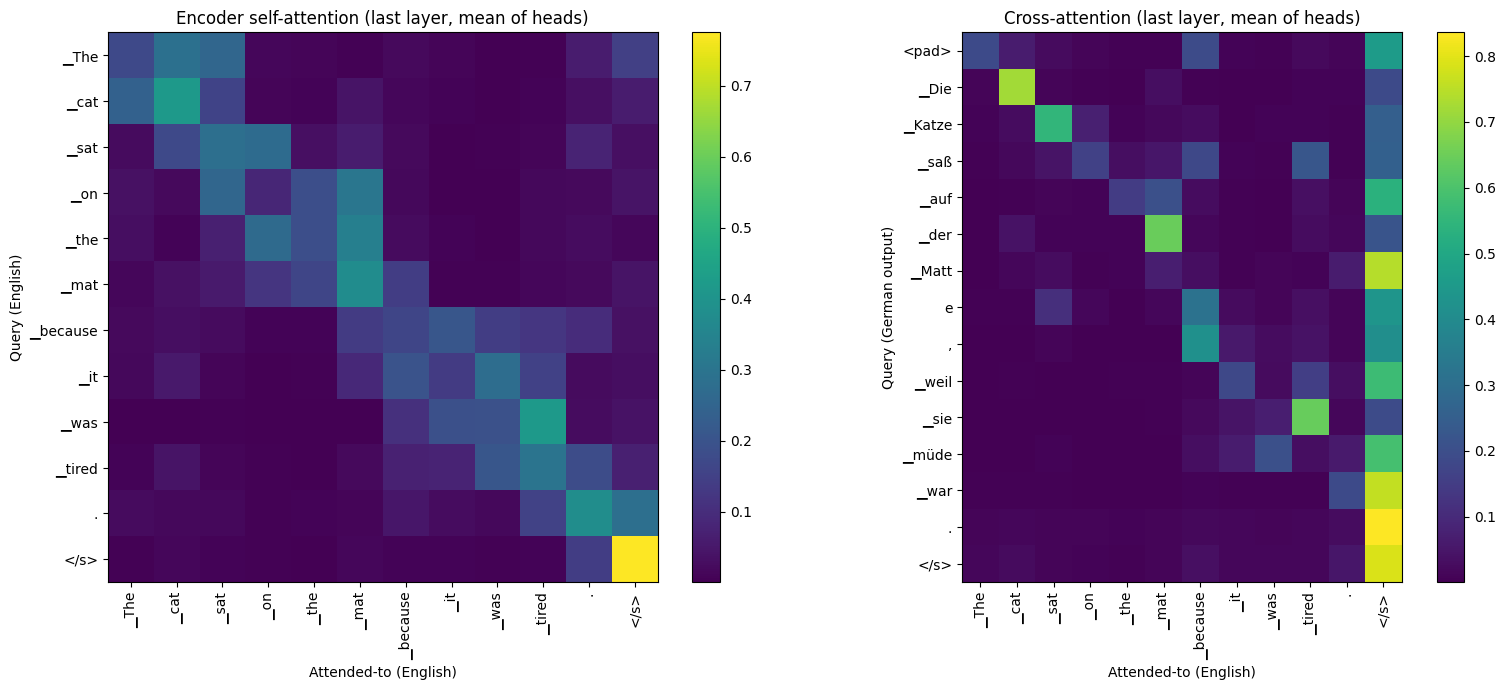

In [23]:
import matplotlib.pyplot as plt

def plot_attn(matrix, xt, yt, title, ax):
    im = ax.imshow(matrix, cmap="viridis")
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt, rotation=90)
    ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)

enc_last = outputs.encoder_attentions[-1][0].mean(0).cpu().numpy()      # (src, src)
cross_last = outputs.cross_attentions[-1][0].mean(0).cpu().numpy()      # (tgt, src)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_attn(enc_last, encoder_tokens, encoder_tokens, "Encoder self-attention (last layer, mean of heads)", axes[0])
plot_attn(cross_last, encoder_tokens, decoder_tokens, "Cross-attention (last layer, mean of heads)", axes[1])
axes[0].set_xlabel("Attended-to (English)"); axes[0].set_ylabel("Query (English)")
axes[1].set_xlabel("Attended-to (English)"); axes[1].set_ylabel("Query (German output)")
plt.tight_layout(); plt.show()

### Analysis

**1. Quality (Transformer vs. LSTM).** The fine-tuned Transformer gives fluent, grammatical German for all 10 sentences. Examples are *Die Katze saß auf der Matte.* and *Ich gehe in die Bibliothek, um ein Buch zu lesen.* The only literal mistakes are the idiom (#5, "wie bei Katzen und Hunden", a word-for-word reading of "raining cats and dogs") and "schnellbraune Fuchs" (#8). The character-level LSTM produces mostly unrelated output ("Ich bin schwarz gewinnen." for three different inputs, "Ich hasst die Arbeitegen." for the cat sentence). It also invents non-words ("Arbeitegen", "gewahren"). It learned German-like character patterns but not the meaning of the source sentence.

**2. BLEU.** The pre-trained model scored 47.29 BLEU on the validation set before fine-tuning. After 3 epochs on 20k pairs it scored 49.74, 50.52 and 50.60 at epochs 1, 2 and 3, a gain of about 3.3 BLEU. The final score on the held-out test set is **49.84** (test loss 0.620). Validation loss fell from 0.776 to 0.600. The gains flatten after epoch 2, so more epochs on this small subset would help little. The baseline and the epoch numbers are validation scores, while 49.84 is the test score, so don't compare 47.29 with 49.84 directly.

**3. Architecture.** The LSTM encoder squeezes the whole sentence into one fixed-size (h, c) state, and the decoder reads that state character by character. Information from the start of a sentence gets overwritten, and training and decoding are sequential. The Transformer uses multi-head self-attention, so every token attends to every other token in one step and long-range dependencies (#4) don't have to survive a recurrent chain. It also uses cross-attention so each output word can look at the relevant source words, runs in parallel, and starts from pre-training on millions of sentence pairs (this model is about 74M parameters). The LSTM here has about 0.7M parameters and was trained on only 10k sentences at the character level.

**4. Attention visualisations.** *Encoder self-attention* (left heatmap): the weights concentrate near the diagonal and on neighbouring words. "cat" attends to "The", "mat" to "the", and "was" and "tired" to each other, so the encoder builds local grammatical context. Several heads also use the final `</s>` token as a sink. *Cross-attention* (right heatmap): German words attend to the English words they translate. "Die" and "Katze" align to "The cat", and "der" aligns to "the mat". The last layer puts much of its weight on `</s>`, which is common for late layers and means the model is mostly using the already-built context there. The alignment follows word order here because English and German word order match for this sentence. In sentences with different order, such as verb-final subordinate clauses, the alignment would be off the diagonal. This is the same idea as the attention in your LSTM (decoder looking at the source), but here it is learned in every layer and every head.
